# Press Start: What 36,000 Steam games reveal about Indie success

**Author:** Omar Mohammed Al-Faifi · Software Engineer
**Dataset:** [Steam Games Dataset — Artemiy Ermilov (Kaggle, March 2025)](https://www.kaggle.com/datasets/artermiloff/steam-games-dataset)

This notebook is the **visual analysis layer** of the project. The heavy lifting lives in plain Python modules
(`src/cleaning.py`, `src/analysis.py`, `src/plots.py`), so the notebook, the Streamlit dashboard and the
presentation all show exactly the same numbers.

| Section | Content |
|---|---|
| 1 | Dataset & problem definition |
| 2 | Data loading & structure |
| 3 | Data quality checks |
| 4 | Cleaning, feature engineering & target |
| 5 | Univariate analysis |
| 6 | Bivariate & multivariate analysis |
| 7 | Answers, insights & limitations |

## 1. Dataset & Problem Definition

**About the dataset.** A snapshot of the Steam store collected in **March 2025** from the Steam Web API and SteamSpy:
~95,000 apps with price, release date, genres, player tags, review counts, playtime, languages, platforms and more.

**Why this dataset?** Steam is where most small studios launch, because it needs no console dev-kit or publisher.
The data lets us ask a question a real developer would ask, instead of only describing a store.

**The persona.** *A small Indie developer with a limited budget who will launch on Steam.*

**Research questions**
1. Are Indie-labelled games less likely to become hits than other games?
2. Which sub-genres give Indie games better odds relative to how crowded they are?
3. Does player satisfaction guarantee visibility?
4. Which product choices are *associated* with Indie hits (price, languages, platforms, multiplayer, achievements)?
5. Are the conclusions robust to how a "hit" is defined?

**Expected insights (written before the analysis).** Most new games are Indie and most get little attention; Indie games
probably have lower odds; crowded genres probably offer worse odds; a high rating alone is probably not enough.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config as C
from src import cleaning, analysis as A, plots

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
%matplotlib inline

## 2. Data Loading & Structure
The original Kaggle file is loaded **without any modification** (`data/raw/games_march2025_full.csv`).

In [2]:
raw = pd.read_csv(C.RAW_FILE, low_memory=False)
raw.head()

,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,header_image,website,support_url,support_email,windows,mac,linux,metacritic_score,metacritic_url,achievements,recommendations,notes,supported_languages,full_audio_languages,packages,developers,publishers,categories,genres,screenshots,movies,user_score,score_rank,positive,negative,estimated_owners,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.00,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,https://shared.akamai.steamstatic.com/store_it...,http://counter-strike.net/,NaN,NaN,True,False,True,0,NaN,1,4401572,Includes intense violence and blood.,"['Czech', 'Danish', 'Dutch', 'English', 'Finni...","['English', 'Indonesian']","[{'title': 'Buy Counter-Strike 2', 'descriptio...",['Valve'],['Valve'],"['Multi-player', 'Cross-Platform Multiplayer',...","['Action', 'Free To Play']",['https://shared.akamai.steamstatic.com/store_...,['http://video.akamai.steamstatic.com/store_tr...,0,NaN,7480813,1135108,100000000 - 200000000,33189,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.00,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.pubg.com,https://support.pubg.com/hc/en-us,NaN,True,False,False,0,NaN,37,1732007,NaN,"['English', 'Korean', 'Simplified Chinese', 'F...",[],[],['PUBG Corporation'],"['KRAFTON, Inc.']","['Multi-player', 'PvP', 'Online PvP', 'Stats',...","['Action', 'Adventure', 'Massively Multiplayer...",['https://shared.akamai.steamstatic.com/store_...,[],0,NaN,1487960,1024436,50000000 - 100000000,0,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.00,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,https://shared.akamai.steamstatic.com/store_it...,http://www.dota2.com/,NaN,NaN,True,True,True,90,https://www.metacritic.com/game/pc/dota-2?ftag...,0,14337,"Dota 2 includes fantasy violence, use of alcoh...","['Bulgarian', 'Czech', 'Danish', 'Dutch', 'Eng...","['English', 'Korean', 'Simplified Chinese', 'V...","[{'title': 'Buy Dota 2', 'description': '', 's...",['Valve'],['Valve'],"['Multi-player', 'Co-op', 'Steam Trading Cards...","['Action', 'Strategy', 'Free To Play']",['https://shared.akamai.steamstatic.com/store_...,['http://video.akamai.steamstatic.com/store_tr...,0,NaN,1998462,451338,200000000 - 500000000,43031,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366
3,271590,Grand Theft Auto V Legacy,2015-04-13,17,0.00,0,"When a young street hustler, a retired bank ro...","When a young street hustler, a retired bank ro...",Grand Theft Auto V for PC offers players the o...,NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.rockstargames.com/V/,https://support.rockstargames.com,NaN,True,False,False,96,https://www.metacritic.com/game/pc/grand-theft...,77,1803063,NaN,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'Spanish - Latin America']","[{'title': 'Buy Shark Cash Cards', 'descriptio...",['Rockstar North'],['Rockstar Games'],"['Single-player', 'Multi-player', 'PvP', 'Onli...","['Action', 'Adventure']",['https://shared.akamai.steamstatic.com/store_...,['http://video.akamai.steamstatic.com/store_tr...,0,NaN,1719950,250012,50000000 - 100000000,19323,771,7101,74,0,117698,"{'Open World':

In [3]:
raw.shape

(94948, 47)

In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94948 entries, 0 to 94947
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     94948 non-null  int64  
 1   name                      94946 non-null  object 
 2   release_date              94948 non-null  object 
 3   required_age              94948 non-null  int64  
 4   price                     94948 non-null  float64
 5   dlc_count                 94948 non-null  int64  
 6   detailed_description      89522 non-null  object 
 7   about_the_game            89499 non-null  object 
 8   short_description         89599 non-null  object 
 9   reviews                   10428 non-null  object 
 10  header_image              94948 non-null  object 
 11  website                   41194 non-null  object 
 12  support_url               44185 non-null  object 
 13  support_email             78848 non-null  object 
 14  window

In [5]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
appid,94948.0,1707530.53,926434.62,20.0,887337.50,1591145.00,2491702.50,3570420.00
required_age,94948.0,0.18,1.70,-1.0,0.00,0.00,0.00,21.00
price,94948.0,6.91,13.07,0.0,0.99,3.99,9.99,999.98
dlc_count,94948.0,0.56,14.92,0.0,0.00,0.00,0.00,3427.00
metacritic_score,94948.0,2.76,14.11,0.0,0.00,0.00,0.00,97.00
achievements,94948.0,19.54,159.80,0.0,0.00,2.00,19.00,9821.00
recommendations,94948.0,1022.21,22741.51,0.0,0.00,0.00,0.00,4401572.00
user_score,94948.0,0.03,1.57,0.0,0.00,0.00,0.00,100.00
score_rank,39.0,99.13,0.70,98.0,99.00,99.00,100.00,100.00
positive,94948.0,1217.90,30979.74,0.0,0.00,8.00,51.00,7480813.00


In [6]:
missing = raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "pct": (missing / len(raw) * 100).round(1)})

,missing,pct
score_rank,94909,100.0
metacritic_url,91372,96.2
reviews,84520,89.0
notes,78296,82.5
website,53754,56.6
support_url,50763,53.5
support_email,16100,17.0
about_the_game,5449,5.7
detailed_description,5426,5.7
short_description,5349,5.6


**Observations**
- 94,948 rows × 47 columns; one row per Steam app. Release dates run from 1997 to March 2025, so the file is a
  **March 2025 snapshot** (the publication date we report).
- Missing values are concentrated in descriptive text and URL columns (website, support links, notes…), which we do not need.
- Many columns are text that contains Python lists/dicts (`genres`, `tags`, `categories`, `supported_languages`) and must be parsed.
- Several numeric columns hide special values (e.g. `-1`), so `isnull()` alone under-reports problems → section 3.

## 3. Data Quality Checks
Before cleaning we test three things that would directly break the definition of a hit.

**3.1 `num_reviews_total = -1`** — is it missing data?

In [7]:
nrt = raw["num_reviews_total"]
print("Rows with -1:", (nrt == -1).sum(), f"({(nrt == -1).mean():.1%})")
print("Smallest real value:", nrt[nrt > 0].min())

Rows with -1: 39575 (41.7%)
Smallest real value: 10


The smallest real value is **10**. Steam does not show a review summary for games with fewer than 10 reviews,
so `-1` means **"fewer than 10 reviews"**, not "unknown". We therefore treat these games as low-visibility (0)
instead of dropping them — dropping 42% of games would hide how hard it is to get noticed.

**3.2 Two review sources** — `positive`/`negative` (SteamSpy) vs `num_reviews_total` (Steam).

In [8]:
pn = raw["positive"] + raw["negative"]
both = (pn > 0) & (nrt > 0)
print("Identical in", f"{(pn[both] == nrt[both]).mean():.1%}", "of games that have both")
cover = raw.assign(year=pd.to_datetime(raw["release_date"]).dt.year, pn_ok=pn > 0)
cover.groupby("year")["pn_ok"].mean().loc[2018:2025].mul(100).round(1).rename("% with SteamSpy votes")

Identical in 14.1% of games that have both


year
2018    96.4
2019    92.6
2020    91.0
2021    78.7
2022    68.6
2023    63.7
2024    58.8
2025    48.1
Name: % with SteamSpy votes, dtype: float64

The two sources rarely match, and SteamSpy coverage collapses for recent games (≈91% in 2020 → ≈64% in 2023).
**Decision:** use only Steam's own `num_reviews_total` and `pct_pos_total`.

**3.3 Test builds and duplicate editions** — some store pages share another game's reviews.

In [9]:
test_builds = raw[raw["name"].str.contains(cleaning.TEST_BUILD_PATTERN, na=False)]
print("Test builds (Playtest / Beta):", len(test_builds))
display(test_builds.nlargest(3, "num_reviews_total")[["name", "release_date", "num_reviews_total"]])
dup = raw[raw.duplicated(["name", "num_reviews_total"], keep=False) & (nrt >= 10000)]
dup.sort_values("num_reviews_total", ascending=False)[["appid", "name", "num_reviews_total"]].head(6)

Test builds (Playtest / Beta): 5247


,name,release_date,num_reviews_total
19,BACKGAMMON Playtest,2023-10-10,716546
22,Baldur's Gate 3 Playtest,2025-01-28,648367
57,NARAKA: BLADEPOINT Playtest,2021-04-16,275877


,appid,name,num_reviews_total
4,488824,Tom Clancy's Rainbow Six® Siege,1168404
7,488823,Tom Clancy's Rainbow Six® Siege,1168404
5,488822,Tom Clancy's Rainbow Six® Siege,1168404
6,488821,Tom Clancy's Rainbow Six® Siege,1168404
180,412020,Metro Exodus,102923
181,1449560,Metro Exodus,102923


Playtests such as *Baldur's Gate 3 Playtest* carry the **main game's** review count, and editions of the same game
(e.g. several Call of Duty® pages) share one review pool. Left in, they would count the same success several times.

## 4. Cleaning, Feature Engineering & Target
All steps live in `src/cleaning.py`. Every step records the row count before and after.

In [10]:
df, log = cleaning.clean(raw, verbose=False)
log

,step,rows_before,rows_after,removed,reason
0,Raw file loaded,94948,94948,0,Original Kaggle file (March 2025 snapshot)
1,Remove test builds,94948,89701,5247,Playtest / beta builds are not released games
2,Remove software,89701,88665,1036,"Only software genres (Utilities, Video Product..."
3,Remove adult content,88665,85162,3503,"Adult genre, adult top-5/top-10 tags, explicit..."
4,Remove duplicate appid,85162,85162,0,Same Steam id listed twice
5,Remove duplicate editions,85162,84970,192,Editions sharing an identical review pool (sam...
6,Remove invalid dates,84970,84970,0,Release date could not be parsed
7,Keep releases 2020–2024,84970,54159,30811,Recent market; 2024 games are used only as a r...


| Step | Why |
|---|---|
| Remove test builds | Not released games; some show the main game's reviews |
| Remove software | Apps whose only genres are tools (Utilities, Video Production…) |
| Remove adult content | Adult genre, Sexual Content / Nudity in the top-5 tags, NSFW / Hentai in the top-10 tags, explicit words in the name, or a short manual list — a separate market, not our persona's |
| Remove duplicate editions | Several pages sharing one identical review pool (same name or same developer) |
| Parse dates | Needed for release year / quarter |
| Keep 2020–2024 | Recent market (2020+ requirement); **2020–2023 = study cohort**, 2024 = robustness check only |

**Feature engineering** (new columns)

| Feature | How it is built | Why |
|---|---|---|
| `review_count`, `few_reviews` | `-1` → 0 and flagged | Visibility, without dropping unseen games |
| `rating_pct` | % positive, only when ≥ 10 reviews | Satisfaction |
| `is_indie` | "Indie" in Steam genres | The developer's own label (not proof of budget) |
| `genres_core`, `subgenres` | Steam genres + top-10 player tags mapped to 40 sub-genres | Competition analysis |
| `price_band`, `is_free` | Price bins | Pricing comparison |
| `n_languages`, `arabic_support`, `n_platforms`, `is_multiplayer`, `has_achievements` | Parsed from list columns | Product choices |
| `days_on_market`, `release_quarter` | From release date | Control for game age |

**Target — `is_hit`.** A game is a hit if its review count is in the **top 5% of games released in the same year**.
Comparing within the year is fair to newer games. Robustness versions: top 10% (`is_hit_top10`) and top 5% within the
release **quarter** (`is_hit_by_quarter`). Reviews measure **visibility, not sales**.

In [11]:
df.head()

,appid,name,developer,release_date,release_year,release_month,release_quarter,cohort,days_on_market,is_indie,is_early_access,is_free,price,price_band,self_published,developer_titles,genres_core,n_genres,subgenres,has_tags,is_multiplayer,n_languages,arabic_support,n_platforms,has_achievements,achievements,has_dlc,required_age,review_count,few_reviews,rating_pct,playtime_hours,peak_ccu,owners_low,owners_high,visibility_pctile,is_hit,is_hit_top10,is_hit_by_quarter,quadrant
0,8980,Borderlands Game of the Year,Gearbox Software,2023-08-31,2023,8,2023Q3,Study 2020–2023,557,False,False,False,29.99,$20+,False,10.0,Action|RPG,2,Shooter|Open World,True,True,5,False,1,True,80,False,17,18896,False,93.0,26.8,136,2000000,5000000,99.4,True,True,True,Popular & Loved
1,12210,Grand Theft Auto IV: The Complete Edition,Rockstar North,2020-03-24,2020,3,2020Q1,Study 2020–2023,1812,False,False,False,6.99,$5–10,False,3.0,Action|Adventure,2,Open World|Shooter,True,True,5,False,1,True,55,False,17,149489,False,82.0,0.0,2593,5000000,10000000,99.8,True,True,True,Popular & Loved
2,45200,Defense of the Oasis,Mind Control Software,2020-08-25,2020,8,2020Q3,Study 2020–2023,1658,False,False,False,4.99,Under $5,False,1.0,Casual|Strategy,2,Turn-Based Strategy,True,False,1,False,1,False,0,False,0,56,False,92.0,0.0,1,200000,500000,72.3,False,False,False,Hidden Gem
3,221680,Rocksmith® 2014 Edition REMASTERED LEARN & PLAY,Ubisoft - San Francisco,2024-12-19,2024,12,2024Q4,Robustness 2024,81,False,False,False,2.99,Under $5,False,2.0,Casual|Simulation,2,Rhythm,True,True,6,False,1,True,47,True,0,14058,False,87.0,50.6,704,1000000,2000000,99.4,True,True,True,Popular & Loved
4,226280,Warp Frontier,Brawsome,2021-09-28,2021,9,2021Q3,Study 2020–2023,1259,True,False,False,14.99,$10–20,True,3.0,Adventure,1,Point & Click|Detective,True,False,4,False,3,True,69,True,0,33,False,87.0,0.2,0,20000,50000,65.1,False,False,False,Not enough reviews


In [12]:
cleaning.save(df, log)
print(df.shape)

Saved -> /Users/ommdh/Desktop/steam-hit-project/data/processed/clean_data.csv
Saved -> /Users/ommdh/Desktop/steam-hit-project/data/processed/cleaning_log.csv
(54159, 40)


In [13]:
study = A.study(df)
numbers = A.overview_numbers(df)
print(f"Study cohort 2020–2023: {numbers['games_study']:,} games · {numbers['hits']:,} hits "
      f"({numbers['hit_rate_all']:.1f}%) · Indie share {numbers['indie_share']:.1f}%")
print("Reviews needed to be a hit, by year:", numbers["hit_threshold_by_year"])

Study cohort 2020–2023: 36,689 games · 1,837 hits (5.0%) · Indie share 70.8%
Reviews needed to be a hit, by year: {2020: 1604.0, 2021: 1781.0, 2022: 1363.0, 2023: 976.0}


The hit line drops from ~1,610 reviews (2020) and ~1,780 (2021) to ~980 (2023): older games had more time to collect reviews.
This is exactly why the hit is defined **within each release year**.

## 5. Univariate Analysis

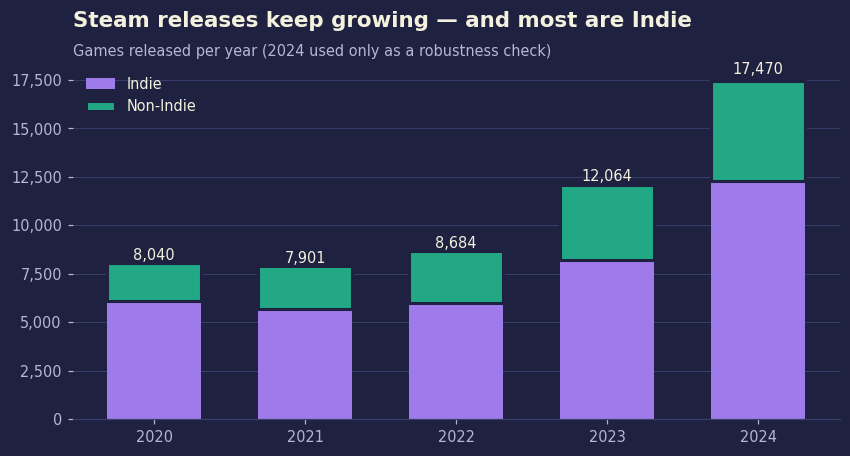

In [14]:
plots.releases_per_year(df);

**Figure 1.** Releases grew from ~8k (2020) to ~17.5k (2024); about 70% carry the Indie label every year. The market is getting more crowded.

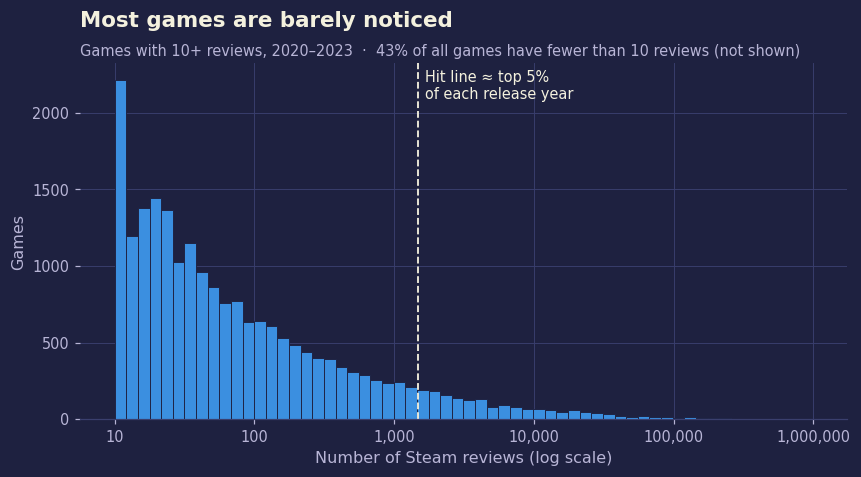

In [15]:
plots.review_distribution(df);

**Figure 2.** Review counts are extremely right-skewed (log scale). 43% of games never reach 10 reviews; the hit line sits far in the tail. Medians, not means, describe a typical game.

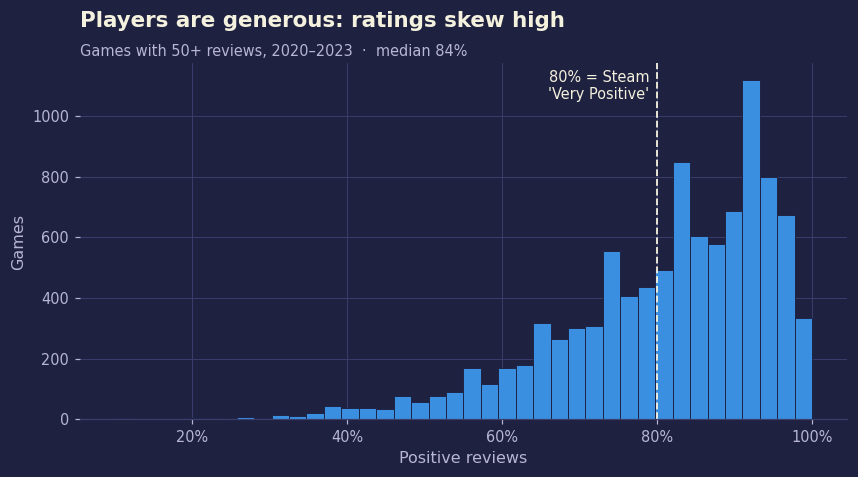

In [16]:
plots.rating_distribution(df);

**Figure 3.** Among games with 50+ reviews the median rating is ~84%: players are generous, so a high rating alone does not separate games much.

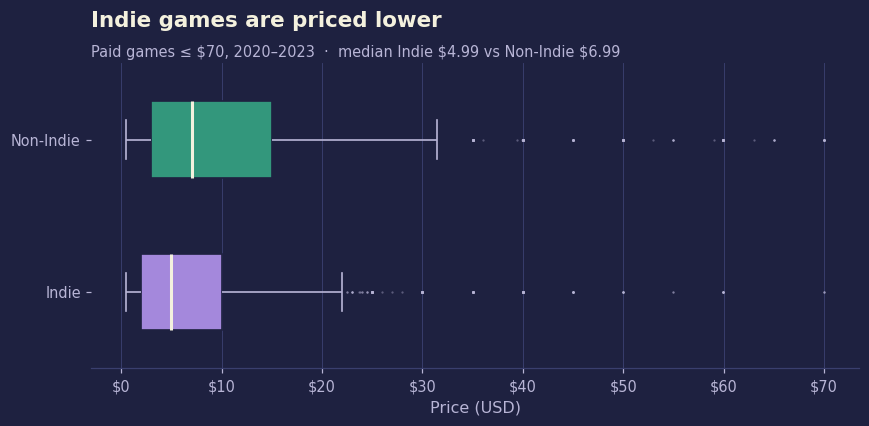

In [17]:
plots.price_by_group(df);

**Figure 4.** Indie games are cheaper (median $4.99 vs $6.99), with a long tail of expensive non-Indie titles (outliers above ~$30).

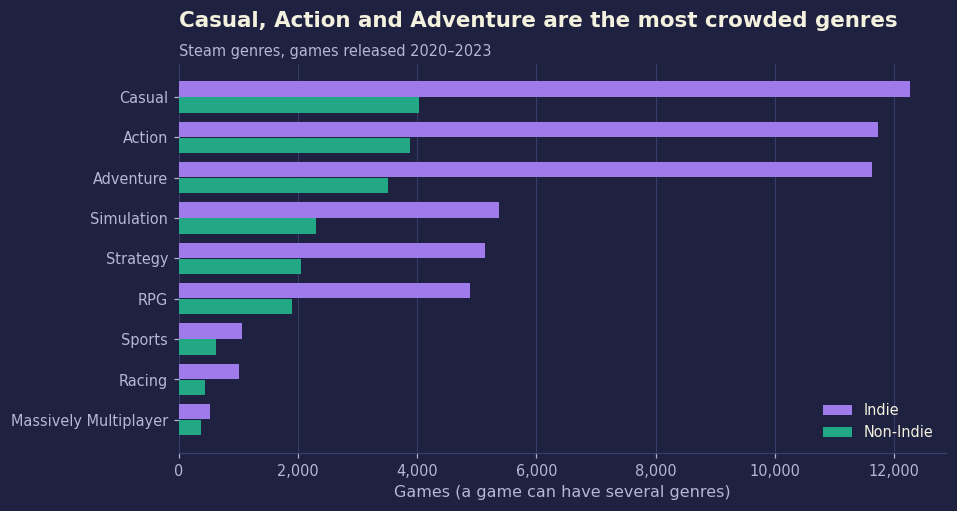

In [18]:
plots.genre_counts(df);

**Figure 5.** Casual, Action and Adventure are by far the most crowded genres — mostly filled by Indie games.

## 6. Bivariate & Multivariate Analysis

### Q1 + Q5 — Are Indie games less likely to become hits? Is it robust?

In [19]:
gap = A.indie_gap(df)
gap.round(2)

,definition,group,games,hits,hit_rate,ci_low,ci_high
0,Top 5% within release year (main),Non-Indie,10723,749,6.98,6.52,7.48
1,Top 5% within release year (main),Indie,25966,1088,4.19,3.95,4.44
2,Top 10% within release year,Non-Indie,10723,1344,12.53,11.92,13.17
3,Top 10% within release year,Indie,25966,2332,8.98,8.64,9.33
4,Top 5% within release quarter,Non-Indie,10723,751,7.00,6.54,7.50
5,Top 5% within release quarter,Indie,25966,1092,4.21,3.97,4.46
6,Top 5% — 2024 releases only,Non-Indie,5204,351,6.74,6.09,7.46
7,Top 5% — 2024 releases only,Indie,12266,523,4.26,3.92,4.64


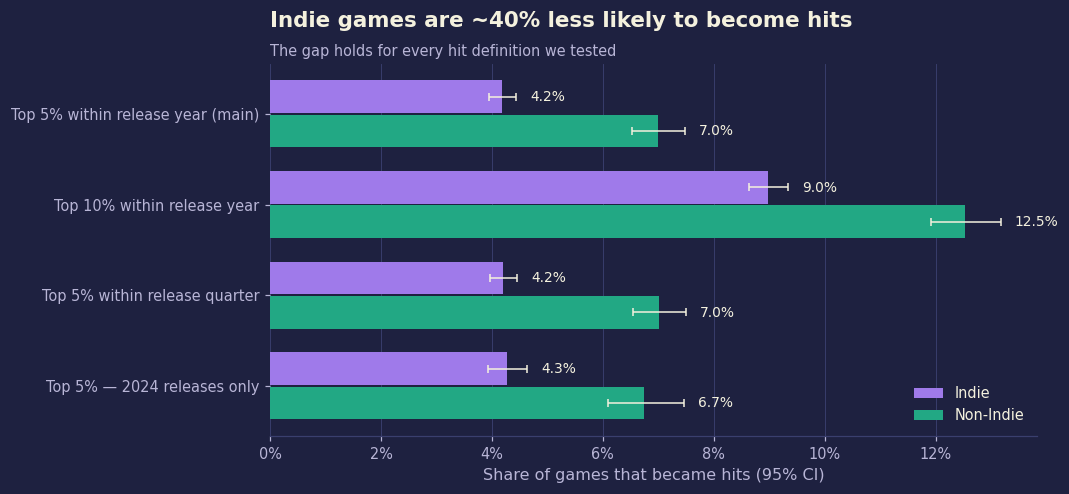

In [20]:
plots.indie_gap(df);

In [21]:
A.indie_share_of_hits(df)

{'share_of_games': np.float64(70.77325628935102),
 'share_of_hits': np.float64(59.227000544365815)}

**Figure 6.** Indie games become hits **4.2%** of the time vs **7.0%** for non-Indie games (95% CIs do not overlap).
Indie games are ~71% of releases but only ~59% of hits. The gap is the same for the top-10% definition,
the per-quarter definition and the 2024 cohort → **not an artefact of one definition**.

### Q2 — Where do Indie games break through? (Opportunity map)

In [22]:
opp, base = A.opportunity_table(df)
print(f"Indie average hit rate (games with tags): {base:.1f}%")
opp.round(1).head(10)

Indie average hit rate (games with tags): 4.3%


,label,games,hits,hit_rate,ci_low,ci_high,vs_average,signal
7,Cozy,96,19,19.8,13.1,28.9,15.4,Above average
6,Colony Sim,212,29,13.7,9.7,19.0,9.3,Above average
19,Management,676,85,12.6,10.3,15.3,8.2,Above average
21,Open World,937,115,12.3,10.3,14.5,7.9,Above average
30,Sandbox,1039,127,12.2,10.4,14.4,7.9,Above average
1,Automation,159,19,11.9,7.8,17.9,7.6,Above average
5,City Builder,386,45,11.7,8.8,15.2,7.3,Above average
11,Farming Sim,244,24,9.8,6.7,14.2,5.5,Above average
9,Deckbuilding,233,22,9.4,6.3,13.9,5.1,Above average
17,Life Sim,502,47,9.4,7.1,12.2,5.0,Above average


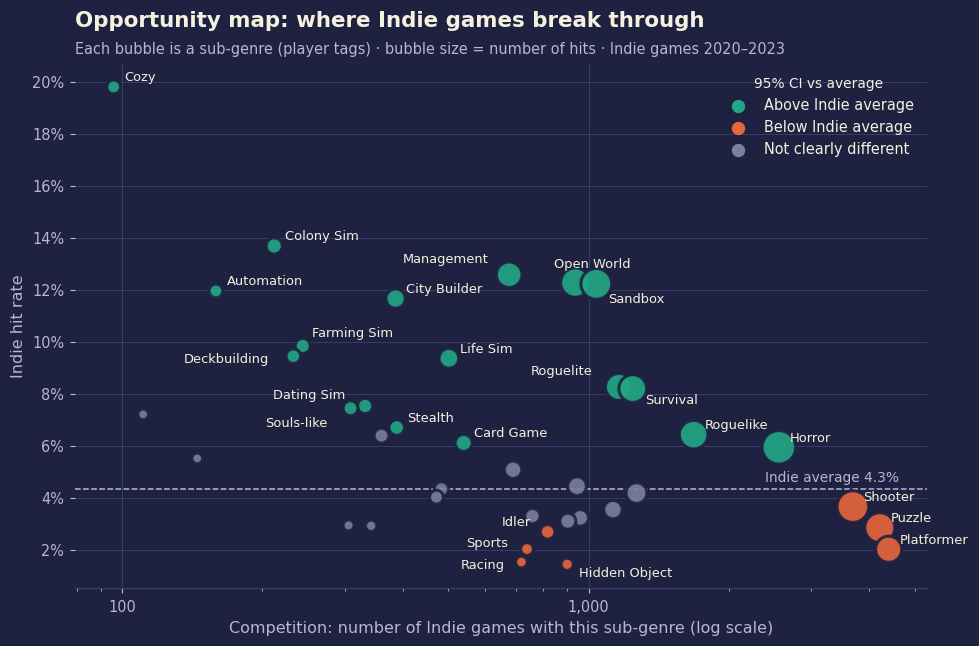

In [23]:
plots.opportunity_map(df);

**Figure 7.** Each bubble is a sub-genre. **Top-left** = fewer competitors and a higher hit rate:
Cozy, Colony Sim, Automation, City Builder, Management, Farming Sim. **Bottom-right** = crowded and below average:
Platformer, Puzzle, Shooter, Hidden Object, Racing, Sports. Colours are only assigned when the 95% CI is entirely above/below the average.
*Caveat:* a small niche can also mean small demand; this is a signal to investigate, not a guarantee.

### Q3 — Does satisfaction guarantee visibility?

In [24]:
A.quadrant_table(df).round(1)

,Non-Indie,Indie,Indie share %
quadrant,,,
Hidden Gem,1226,3554,74.4
Low Traction,1055,2205,67.6
Popular & Loved,438,915,67.6
Popular but Divisive,311,173,35.7


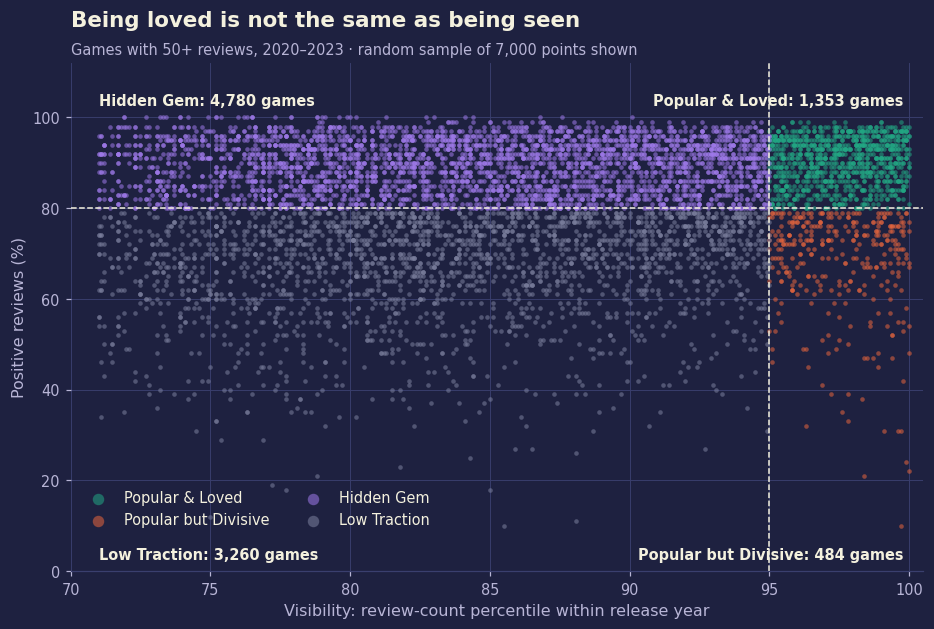

In [25]:
plots.popularity_vs_satisfaction(df);

**Figure 8.** There are ~3.5 **Hidden Gems** (≥80% positive, not hits) for every **Popular & Loved** game.
Quality is common; visibility is rare. *Popular but Divisive* hits are mostly non-Indie (big games can succeed without being loved).

### Q4 — What do Indie hits have in common?

In [26]:
A.feature_effects(df).round(1)

,level,games,hits,hit_rate,ci_low,ci_high,factor
0,Free,4048,226,5.6,4.9,6.3,Price
1,Under $5,12239,140,1.1,1.0,1.3,Price
2,$5–10,5213,152,2.9,2.5,3.4,Price
3,$10–20,3710,368,9.9,9.0,10.9,Price
4,$20+,756,202,26.7,23.7,30.0,Price
5,1,14178,225,1.6,1.4,1.8,Languages
6,2–4,5708,118,2.1,1.7,2.5,Languages
7,5–9,2823,226,8.0,7.1,9.1,Languages
8,10+,3239,519,16.0,14.8,17.3,Languages
9,2 platforms,3358,226,6.7,5.9,7.6,Platforms


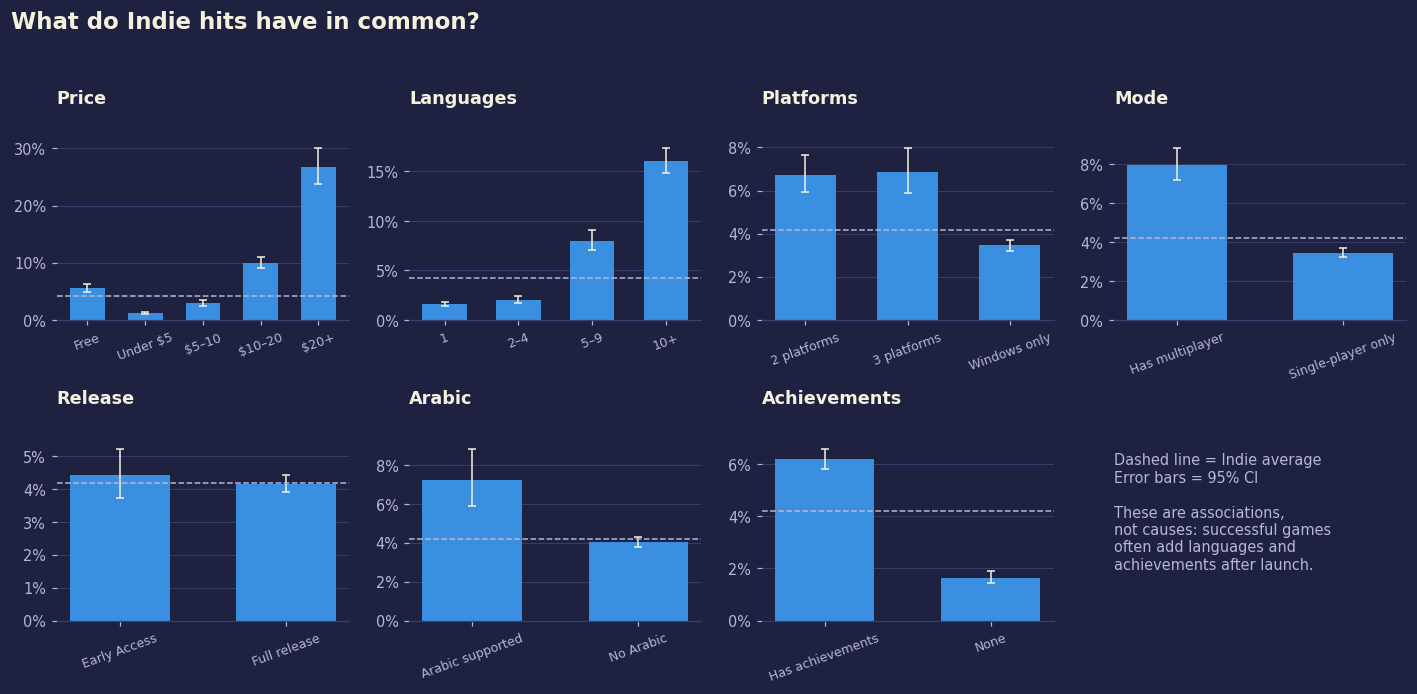

In [27]:
plots.feature_effects(df);

**Figure 9.** Indie hits are associated with higher prices ($20+: ~27% hit rate vs ~1% under $5), 10+ languages, multiple
platforms, multiplayer modes and achievements. **These are associations, not causes:** higher prices usually mean bigger
budgets, and successful games often add languages and achievements *after* launch (reverse causality).
Arabic support is also associated with more hits (7.2% vs 4.0%) — interesting for a Saudi developer, with the same caveat.

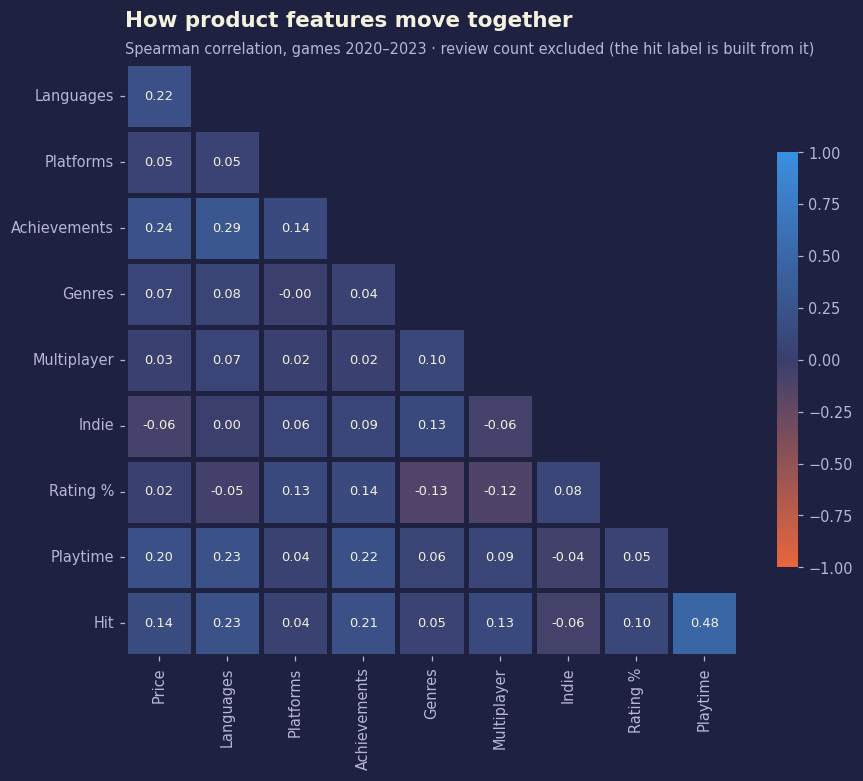

In [28]:
plots.correlation_heatmap(df);

**Figure 10.** Spearman correlations (robust to skew). The hit label is most related to playtime (0.48, an outcome itself),
languages (0.23) and achievements (0.21). Price and rating are almost unrelated (0.02). Review count is excluded because the
hit label is built from it — including it would create an artificial correlation.

## 7. Answers, Insights & Limitations

In [29]:
g = gap[gap["definition"].str.contains("main")].set_index("group")
answers = pd.DataFrame({
    "Question": ["Q1 Indie vs non-Indie hit rate", "Q2 Best / worst sub-genres (Indie)",
                 "Q3 Hidden Gems per Popular & Loved", "Q4 Strongest associations",
                 "Q5 Robust to hit definition?"],
    "Answer": [f"{g.loc['Indie','hit_rate']:.1f}% vs {g.loc['Non-Indie','hit_rate']:.1f}%",
               f"{', '.join(opp.head(3)['label'])} / {', '.join(opp.tail(3)['label'])}",
               f"{(study['quadrant']=='Hidden Gem').sum() / (study['quadrant']=='Popular & Loved').sum():.1f}",
               "Price band, languages, achievements, multiplayer (associations)",
               "Yes — same gap for top 5%, top 10%, per quarter, and 2024"],
})
answers

,Question,Answer
0,Q1 Indie vs non-Indie hit rate,4.2% vs 7.0%
1,Q2 Best / worst sub-genres (Indie),"Cozy, Colony Sim, Management / Platformer, Rac..."
2,Q3 Hidden Gems per Popular & Loved,3.5
3,Q4 Strongest associations,"Price band, languages, achievements, multiplay..."
4,Q5 Robust to hit definition?,"Yes — same gap for top 5%, top 10%, per quarte..."


### Key takeaways for a small Indie developer
1. **Visibility is the real bottleneck.** 43% of games get fewer than 10 reviews; a high rating is common but does not bring an audience.
2. **The Indie label starts behind:** ~40% lower odds of becoming a hit than non-Indie games.
3. **Choose the battlefield.** Systems-driven niches (Cozy, Colony Sim, Management, Automation, City Builder) show higher
   hit rates with less competition than crowded Platformer / Puzzle / Hidden Object games.
4. **Reach matters:** more languages (including Arabic), more platforms and multiplayer are associated with hits — worth testing,
   not proven causes.

### Limitations
- Reviews measure **visibility, not sales or profit**; estimated owners are wide SteamSpy ranges and were not used as sales.
- One snapshot (March 2025): prices, languages and achievements are current values, not launch values.
- "Indie" is a self-chosen Steam label, not a verified studio size or budget.
- Player tags are missing for ~20% of games (mostly unseen ones), so sub-genre results describe games that got at least some attention.
- The adult-content filter uses the top-5 player tags, so it also removes some mainstream games with nudity tags (e.g. Cyberpunk 2077, Atomic Heart, Wasteland 3). This does not change the main conclusions. A few adult games may remain.
- Observational data: correlations, not causes.

### Future work
- Track games from launch with time-stamped review data to remove the age effect completely.
- Use review text (NLP) to learn *why* Hidden Gems are loved but not found.
- Add marketing signals (wishlists, trailers, festival participation) if data becomes available.

## 8. Predictive model (bonus)
**Goal:** estimate the chance that a game becomes a hit (`is_hit`) from choices a developer makes **before launch**.
All logic lives in `src/model.py`; `python -m src.model` retrains and saves `models/hit_model.joblib` + `models/metrics.json`.

**Features (pre-launch only):** price band (Free, under $5, $5–10, $10–20, $20+, one-hot), Indie label, Early Access,
multiplayer, number of platforms, release month, Steam core genres (one-hot) and sub-genres (one-hot from player tags).
Price enters as bands, not as a straight line, so the model cannot claim that every extra dollar raises the chance.

**Deliberately excluded:** languages, achievements and DLC are often added *after* a game succeeds (reverse causality);
playtime, reviews, rating, owners and peak players are measured after launch; `visibility_pctile`, `quadrant` and the
`is_hit_*` columns are built from the review count, i.e. from the target itself (leakage).

In [30]:
from src import model as M

bundle, metrics = M.load_model()          # trained by `python -m src.model`
s = M.load_data(df)                       # 2020–2023 study cohort
train, test = M.split(s)                  # same stratified 80/20 split (random_state=42)
print(f"Study games: {len(s):,} · train {len(train):,} · test {len(test):,}")
print(f"Hit rate — train {train['is_hit'].mean():.1%} · test {test['is_hit'].mean():.1%}")

Study games: 36,689 · train 29,351 · test 7,338
Hit rate — train 5.0% · test 5.0%


**Split and tuning.** Stratified 80/20 split; the test set is used **once**, at the very end. Scaling and one-hot
encoding live inside a scikit-learn `Pipeline`, so they are fitted on training data only. `C` (L2 strength) is tuned with
5-fold stratified cross-validation on the training set (ROC-AUC). `class_weight="balanced"` handles the 5% hit rate, and
`CalibratedClassifierCV` (sigmoid, inside the training data) turns scores into realistic probabilities.

In [31]:
pd.DataFrame(metrics["cv_grid"]).rename(columns={"cv_auc": "CV ROC-AUC", "cv_std": "CV std",
                                                "train_auc": "Train ROC-AUC (CV folds)"})

,C,CV ROC-AUC,CV std,Train ROC-AUC (CV folds)
0,0.01,0.8303,0.0089,0.8374
1,0.03,0.8310,0.0085,0.8398
2,0.10,0.8310,0.0081,0.8410
3,0.30,0.8308,0.0078,0.8414
4,1.00,0.8308,0.0077,0.8416
5,3.00,0.8307,0.0077,0.8416


**Overfitting check:** train vs cross-validation vs test ROC-AUC (flag if train is more than 0.03 above test).

In [32]:
t = metrics["test"]
pd.DataFrame({
    "Metric": ["Train ROC-AUC", "CV ROC-AUC (mean ± std)", "Test ROC-AUC", "Train − test gap",
               "Time check: 2020–22 → 2023 ROC-AUC", "Test average precision", "Test Brier score",
               "Hit rate in top 10% predicted (test)", "Base hit rate (test)", "Chosen C"],
    "Value": [metrics["train_auc"], f"{metrics['cv_auc_mean']} ± {metrics['cv_auc_std']}",
              t["roc_auc"], f"{metrics['overfit_gap']} ({'FLAG' if metrics['overfit_flag'] else 'ok'})",
              metrics["time_check"]["roc_auc"], t["average_precision"], t["brier"],
              f"{t['top10_hit_rate_pct']}%", f"{t['base_rate_pct']}%", metrics["best_C"]]})

,Metric,Value
0,Train ROC-AUC,0.839
1,CV ROC-AUC (mean ± std),0.831 ± 0.009
2,Test ROC-AUC,0.838
3,Train − test gap,0.001 (ok)
4,Time check: 2020–22 → 2023 ROC-AUC,0.824
5,Test average precision,0.279
6,Test Brier score,0.0412
7,Hit rate in top 10% predicted (test),24.8%
8,Base hit rate (test),5.0%
9,Chosen C,0.03


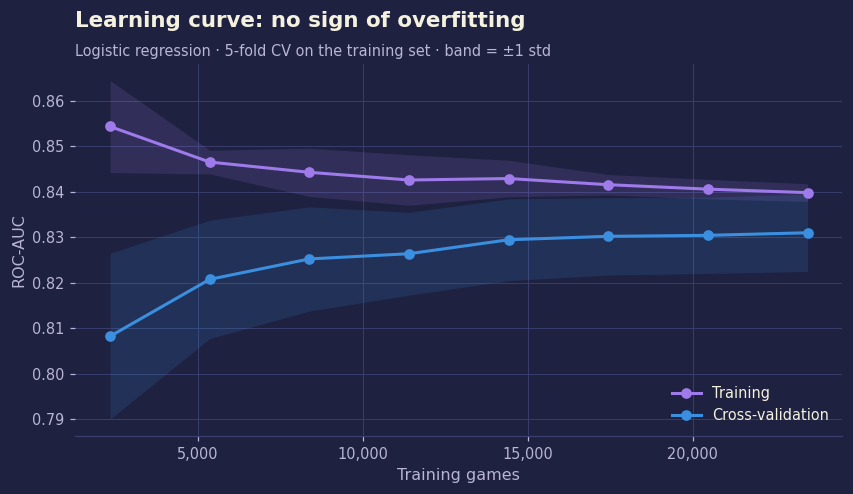

In [33]:
lc = M.learning_curve_table(train, metrics["best_C"])
plots.learning_curve(lc);

**Learning curve.** Training and cross-validation scores converge as data grows and the gap stays small: the model
is not memorising the training set. More data would add little, so the limit is the information in pre-launch features.

**Comparison model: Random Forest** (max depth 6–10, min 20–50 games per leaf), tuned and calibrated the same way.

In [34]:
rf = M.random_forest_comparison(train, test)
pd.DataFrame({
    "Logistic regression": [f"C = {metrics['best_C']}", metrics["train_auc"],
                            f"{metrics['cv_auc_mean']} ± {metrics['cv_auc_std']}", t["roc_auc"],
                            t["average_precision"], t["brier"]],
    "Random forest": [", ".join(f"{k}={v}" for k, v in rf["best_params"].items()), rf["train_auc"],
                      f"{rf['cv_auc_mean']} ± {rf['cv_auc_std']}", rf["test_auc"],
                      rf["average_precision"], rf["brier"]]},
    index=["Settings", "Train ROC-AUC", "CV ROC-AUC", "Test ROC-AUC", "Average precision", "Brier"])

,Logistic regression,Random forest
Settings,C = 0.03,"max_depth=10, min_samples_leaf=20"
Train ROC-AUC,0.839,0.858
CV ROC-AUC,0.831 ± 0.009,0.832 ± 0.008
Test ROC-AUC,0.838,0.836
Average precision,0.279,0.298
Brier,0.0412,0.0408


Both models reach almost the same test ROC-AUC. The forest ranks the very top a little better (higher average precision,
lower Brier score) but fits the training data more closely (larger train − test gap) and cannot show *why* it scores a
game. The dashboard uses the logistic regression: almost the same accuracy, a smaller gap, and every factor can be explained.

In [35]:
cm = t["confusion"]
print(f"Threshold = {t['threshold']:.3f} (top 10% of predicted chances on the TRAINING set)")
pd.DataFrame([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]],
             index=["Actual: not hit", "Actual: hit"], columns=["Predicted: not hit", "Predicted: hit"])

Threshold = 0.125 (top 10% of predicted chances on the TRAINING set)


,Predicted: not hit,Predicted: hit
Actual: not hit,6431,540
Actual: hit,188,179


Precision 0.25 · recall 0.49 at this threshold


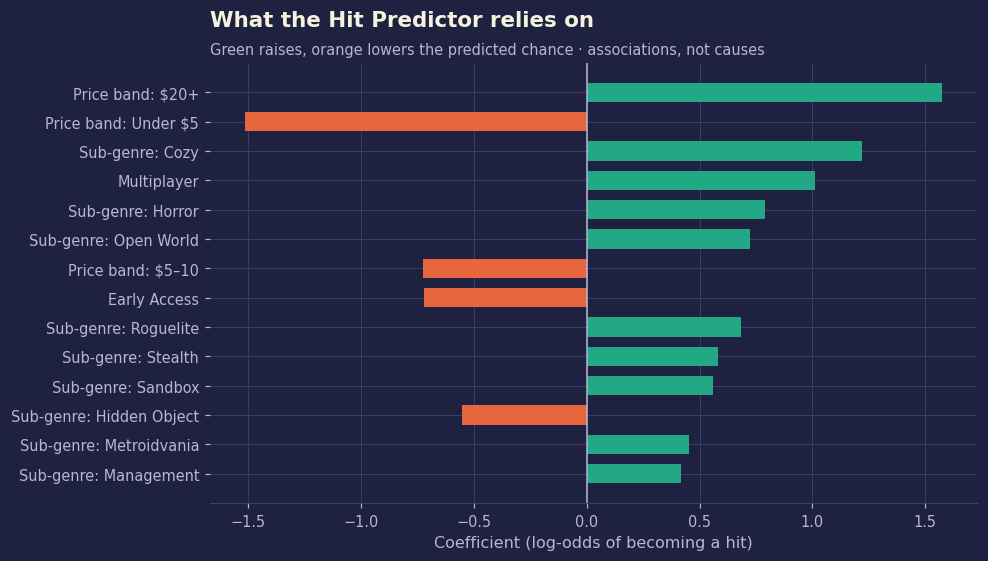

In [36]:
print(f"Precision {t['precision_at_threshold']:.2f} · recall {t['recall_at_threshold']:.2f} at this threshold")
plots.model_coefficients(M.coefficients(bundle["explainer"]));

**Reading the model.** Flagging the top 10% of predicted chances finds hits about **five times** more often than the
5% base rate, but most flagged games still do not become hits: pre-launch choices shift the odds, they do not decide
them. Coefficients are **associations, not causes**. Price in particular is a **confounder**: it stands for budget and scope
(bigger teams, more content, more marketing), so raising the price of the same game would not make it a hit. The time check
— trained on 2020–2022, tested on 2023 — stays close to the random-split score, so the patterns hold for a newer year.